# STAGE: Spatio-Temporal Allelic Geostatistic Estimation
**Part 2: Spatiotemporal Variogram Fitting**

Geostatistics was originally designed for continuous numerical data (like temperature or elevation). The STAGE framework bridges this gap, allowing us to perform spatiotemporal geostatistical analysis on **categorical genetic data** (e.g., *Avr-Pik* variants).

This notebook run the STAGE framework using a simulated data. We will:
1. Calculate empirical spatiotemporal variograms across multiple years using a simulated *Avr-Pik* sample dataset.
2. Fit a theoretical Spherical model to extract spatial parameters (Range, Sill, Nugget).

## 1. Setup the Environment

**Instructions for Reviewers:**
This notebook is fully automated to run in a temporary Colab environment. The first code cell will configure the workspace, install necessary geostatistical libraries (such as `scikit-gstat`), and automatically download the required datasets (sage_spatiotemporal_sample_data.csv; avrpik_gt_distmatdf.csv).

Simply select **Runtime > Run all** from the top menu to execute the entire pipeline.

In [1]:
!pip install numpy pandas scipy scikit-learn scikit-gstat matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 710.3/710.3 kB 3.5 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import math

from scipy.spatial import distance_matrix
from scipy.optimize import curve_fit
from skgstat.models import spherical
from sklearn.metrics import r2_score, root_mean_squared_error

import matplotlib.pyplot as plt
import seaborn as sns

# Download the sample data to run SAGE in the Colab environment
!gdown "1bJFR6TXhEgeFPXj-dT_r8tZL_KIOi16K" -O stage_spatiotemporal_sample_data.csv

# Download the genetic distance matrix file
!gdown "1Vx8vU1Jb2vrLcPA0ahk9jEfhrqMA8837" -O avrpik_gt_distmatdf.csv



Downloading...
From: https://drive.google.com/uc?id=1bJFR6TXhEgeFPXj-dT_r8tZL_KIOi16K
To: /content/stage_spatiotemporal_sample_data.csv
100% 10.3k/10.3k [00:00<00:00, 37.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Vx8vU1Jb2vrLcPA0ahk9jEfhrqMA8837
To: /content/avrpik_gt_distmatdf.csv
100% 585/585 [00:00<00:00, 2.90MB/s]


## 2. Calculate Empirical Variograms

To test our framework, we used a simulated data set with 100 sampling locations across a landscape and 3 years (2015-2017).

The functions below calculate the pairwise geographic distance and genetic variance between every possible pair of samples across different years. We then "bin" these distances into specific spatial **lags** (e.g., grouping all farm-pairs that are 0-5km apart, 5-10km apart, etc.) to calculate the average genetic variance at that distance.

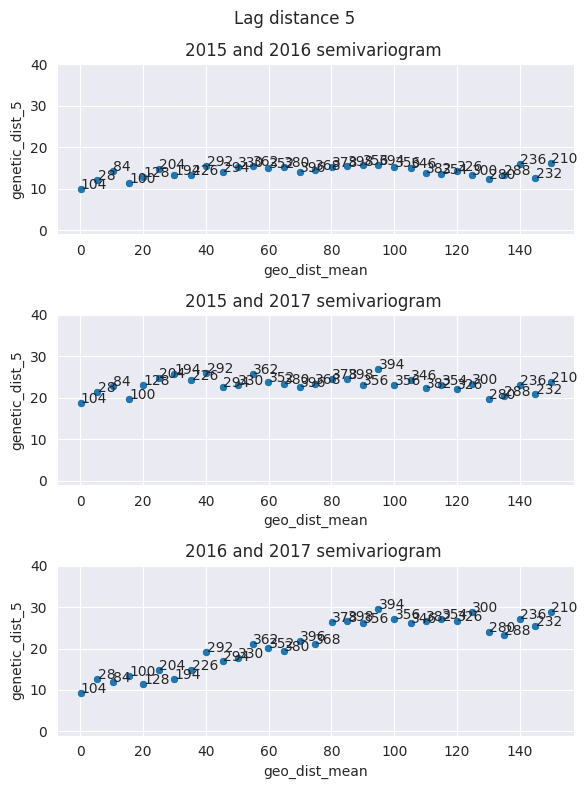

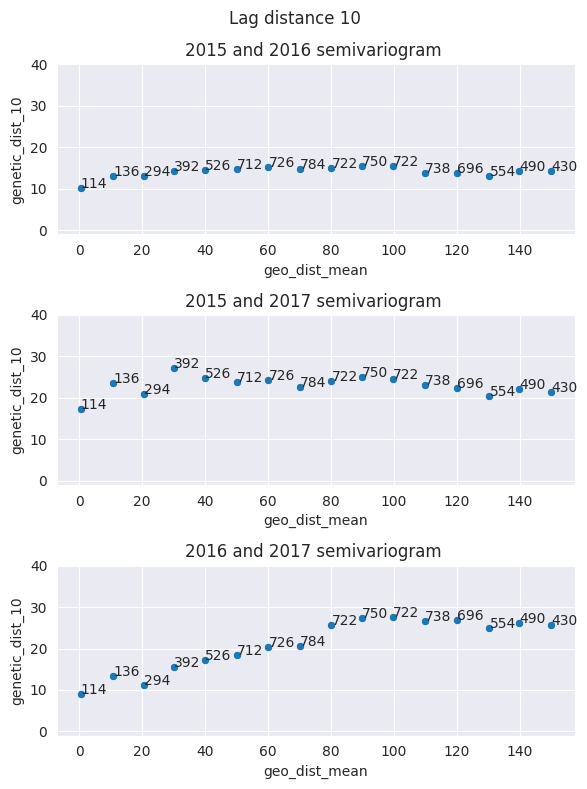

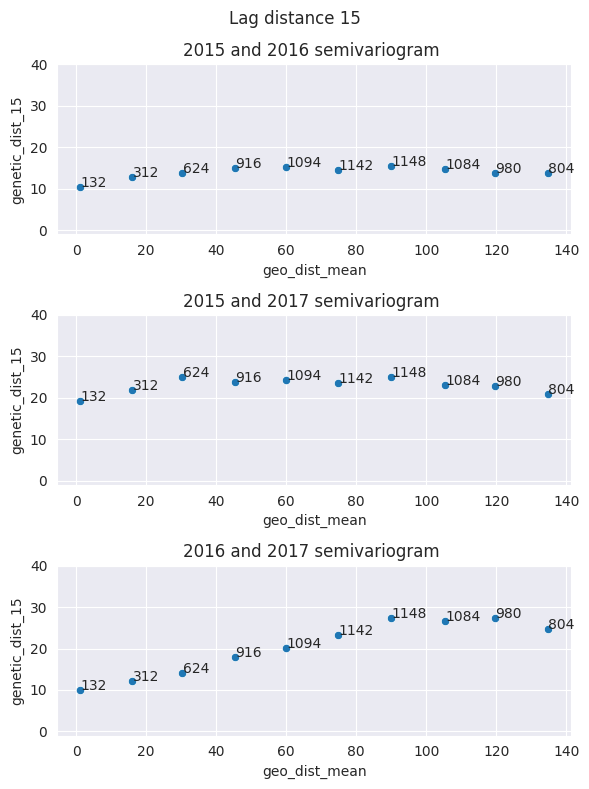

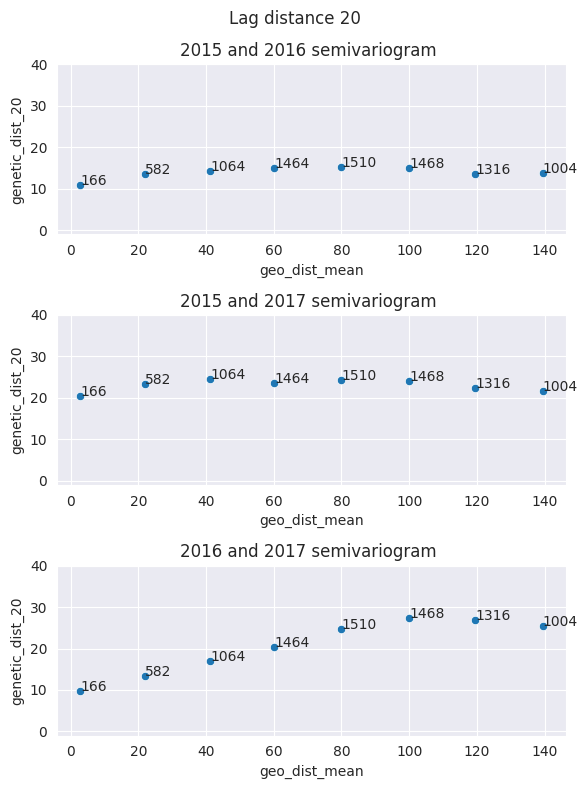

In [3]:
def stgenevariance(gt_coords_df, gt_distmat):
    "calculate spatial temporal genetic variance"
    years = gt_coords_df['Year'].unique()
    sample_sizes = gt_coords_df.groupby(by=['Year'])['Genotype'].agg(sample_size='count')

    yearis = [] # store year of one layer
    yearjs = [] # store year of another layer
    ks = [] # store kth sample of one layer
    ls = [] # store lth sample of another layer
    genetic_dists = [] #store the semi-variance of two points
    geo_dists = [] # store geographical distance of two points

    for i in range(len(years)):
        yeari = years[i]
        sample_sizei = sample_sizes.at[yeari, 'sample_size']
        gt_coords_yeari = gt_coords_df[gt_coords_df['Year']==yeari].reset_index()

        for j in range(i+1, len(years)):
            yearj = years[j]
            sample_sizej = sample_sizes.at[yearj, 'sample_size']
            gt_coords_yearj = gt_coords_df[gt_coords_df['Year']==yearj].reset_index()

            "calculate pairwise distances between points from yeari and yearj"
            for k in range(sample_sizei): # point at layer i
                gtk = gt_coords_yeari.at[k,'Genotype']
                xcoordk = gt_coords_yeari.at[k,'CoordX']
                ycoordk = gt_coords_yeari.at[k,'CoordY']

                for l in range(sample_sizej): #point at layer j
                    gtl = gt_coords_yearj.at[l,'Genotype']
                    xcoordl = gt_coords_yearj.at[l,'CoordX']
                    ycoordl = gt_coords_yearj.at[l,'CoordY']

                    "calculate genetic variance"
                    gene_dist = gt_distmat.at[gtk, gtl]
                    gene_variance = (gene_dist ** 2) * 0.5  # semi-variance

                    "calculate samples geographic distance"
                    geo_dist = math.dist([xcoordk, ycoordk],[xcoordl, ycoordl])

                    yearis.append(yeari)
                    yearjs.append(yearj)
                    ks.append(k)
                    ls.append(l)
                    genetic_dists.append(gene_variance)
                    geo_dists.append(geo_dist)


    space_time_semivar_df = pd.DataFrame(data={'yeari':yearis, 'yearj':yearjs,
                                               'sample_yeari_k':ks, 'sample_yearj_l':ls,
                                               'genetic_dist':genetic_dists,
                                               'geo_dist':geo_dists})

    return space_time_semivar_df


def binningaverage(vario_df, lag):
    "binning and group into lags"
    vario_df = vario_df.sort_values(by=['yeari', 'yearj', 'geo_dist'])
    vario_df["lag"] = vario_df["geo_dist"].apply(lambda x: math.ceil((x - 0.5 * lag) / lag)) # the first bin is [0, 0.5*lag]

    "calculate mean values by group"
    vario_gpdf = vario_df.groupby(['yeari', 'yearj', 'lag']).agg(genetic_dist_mean=("genetic_dist", "mean"),
                                               geo_dist_mean=("geo_dist", "mean"),
                                               pair_count=("genetic_dist", "count")).reset_index()

    "create a new column to save the genetic variance"
    gencol = "genetic_dist_" + str(lag)
    vario_gpdf[gencol] = vario_gpdf["genetic_dist_mean"]

    return vario_gpdf




sns.set_style("darkgrid")

"import the genetic distance matrix"
gt_distmat = pd.read_csv("avrpik_gt_distmatdf.csv", index_col=0)

"import genotype sample data"
gt_coords_df = pd.read_csv("stage_spatiotemporal_sample_data.csv")

"calculate genetic variogram"
stvario_df_all = stgenevariance(gt_coords_df, gt_distmat)

"explore lag distances"
lags = [5, 10, 15, 20]

for i in range(len(lags)):
    lag = lags[i]
    fig, axs = plt.subplots(3, figsize=(6, 8))

    "years association"
    yearpair = stvario_df_all[['yeari', 'yearj']].drop_duplicates().reset_index()
    for idx, dfrow in yearpair.iterrows():
        "get data for corresponding year"
        yeari = dfrow['yeari']
        yearj = dfrow['yearj']
        stvario_df = stvario_df_all[(stvario_df_all['yeari']==yeari) & (stvario_df_all['yearj']==yearj)]

        "binning and average of variance"
        stvario_gpdf = binningaverage(stvario_df, lag)

        "save these variogram files"
        stvario_df.to_csv("vario_df_" + str(yeari) +  '_' + str(yearj) + ".csv")
        stvario_gpdf.to_csv("vario_group_df_" + str(lag)  + '_' + str(yeari) +  '_' + str(yearj) + ".csv")

        "plot genetic variance to distance"
        gencol = "genetic_dist_" + str(lag)
        stvario_gpdf = stvario_gpdf[stvario_gpdf['geo_dist_mean']<=150]
        subplot = sns.scatterplot(x=stvario_gpdf['geo_dist_mean'], y=stvario_gpdf[gencol], ax=axs[idx])

        "add point label"
        for i, point in stvario_gpdf.iterrows():
            subplot.text(point['geo_dist_mean'] + 0.1, point[gencol], int(point['pair_count']))

        axs[idx].set_ylim(-1, 40)
        axs[idx].set_title(str(yeari) + ' and ' + str(yearj) + ' semivariogram ')



    fig.suptitle("Lag distance " + str(lag))
    fig.tight_layout()
    fig.savefig("spatiotemporal_varigrams_lag_" + str(lag) + ".png", dpi=300)

## 3. Fit the Theoretical Spherical Model

An empirical variogram shows us the raw data points, but to extract meaningful epidemiological metrics, we must fit a theoretical model to these points. We use a **Spherical Model**, wrapped using `scipy.optimize.curve_fit`.

This optimization allows us to extract three critical parameters of the disease spread:
* **Range ($a$):** The distance at which genetic correlation stops. Beyond this distance, pathogen populations are genetically independent.
* **Partial Sill ($b$):** The maximum genetic variance (the plateau of the curve).
* **Nugget ($c$):** The y-intercept, representing micro-scale genetic variation or sampling error at a distance of zero.

Below, we iterate through multiple lag distances (5, 10, 15, 20 km) to evaluate model performance across different spatial granularities, recording the RMSE, R-squared, and AIC for each fit.

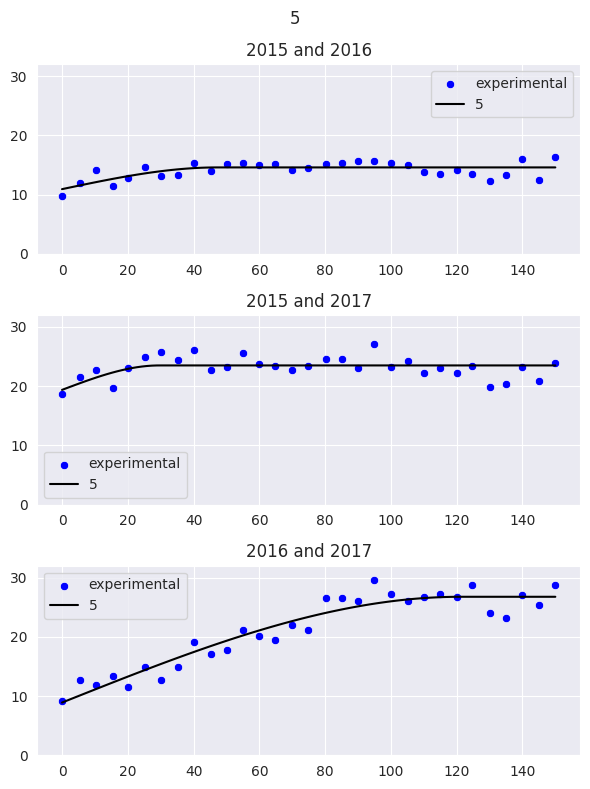

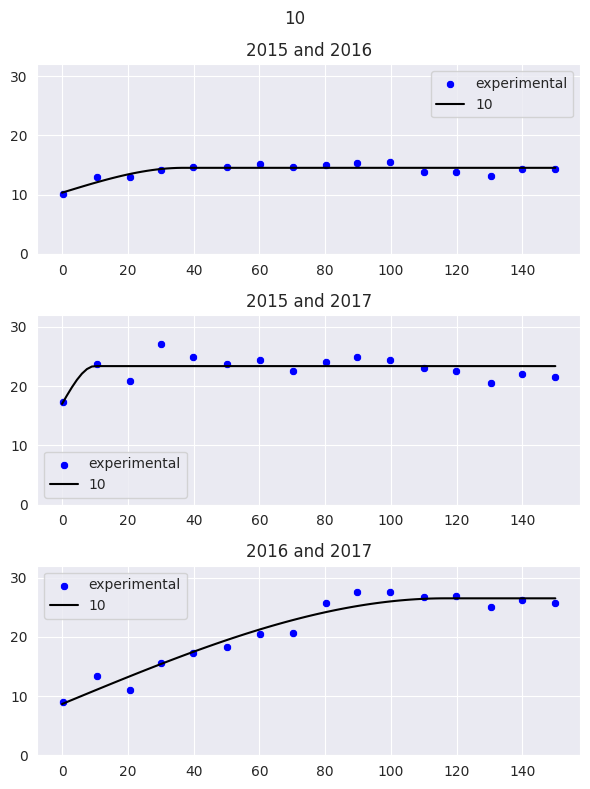

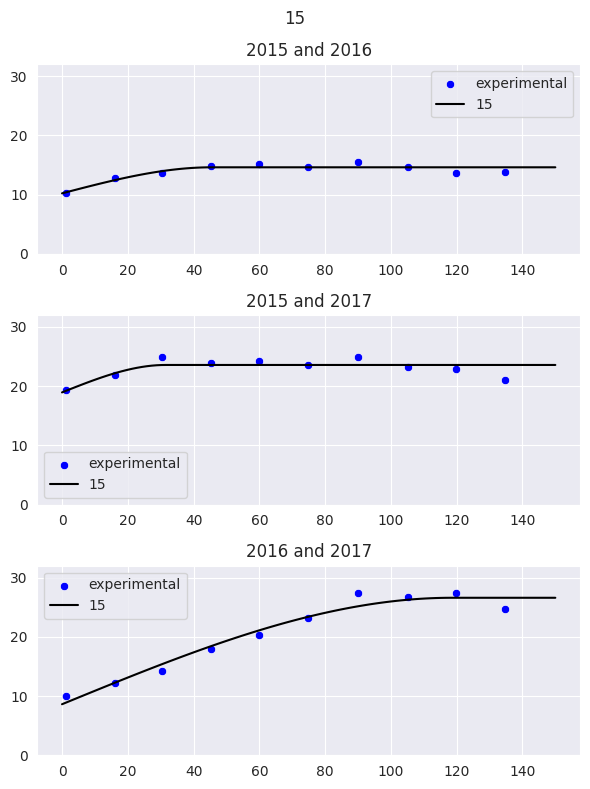

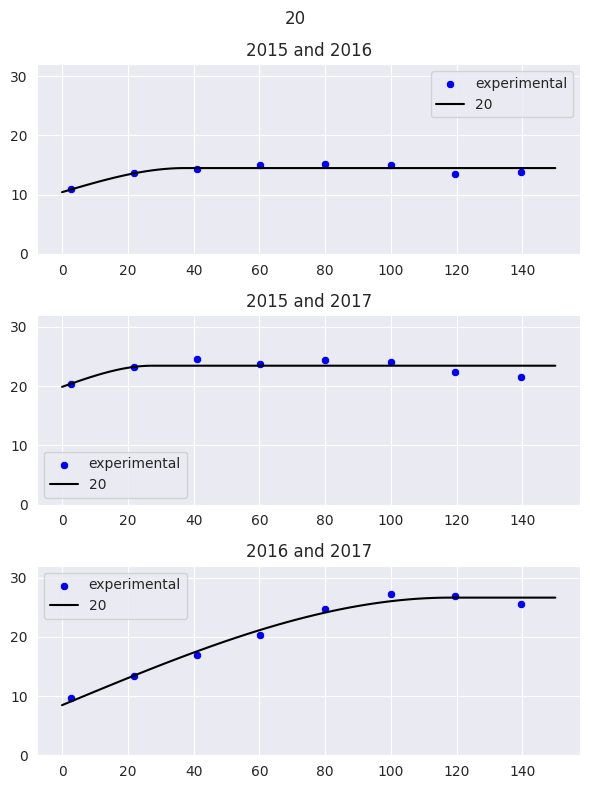

In [4]:
def f(x, a, b, c):
    """
    As the spherical function is compiled using numba, we wrap the function
    in order to let curve_fit correctly infer the parameters.

    In default, the parameter nugget (here is c) is 0

    """

    return spherical(x, a, b, c)


years = [2015, 2016, 2017]
lags = [5, 10, 15, 20]

sns.set_style('darkgrid')

"explore model fitting by lag"
lag_lst = []
yeari_lst = []
yearj_lst = []
p00_lst = [] # initial value for the effective range
p01_lst = [] # initial value for the partial sill of the variogram
p02_lst = [] # initial value for the nugget of the variogram
cof0_lst = [] #estimated value the effective range
cof1_lst = [] #estimated value for the partial sill of the variogram
cof2_lst = [] #estimated value for the nugget of the variogram
cov0_lst = [] #standard error of the effective range
cov1_lst = [] #standard error of the partial sill
cov2_lst = [] #standard error of the nugget
rmse_lst = [] # rmse
r2_lst = []
aics = []
num_lags_lst = []
infodicts = []


for i in range(len(lags)):
    lag = lags[i]
    fig, axs = plt.subplots(3, figsize=(6, 8))

    l = 0 #locate the fig row
    for j in range(len(years)-1):
        "get data for corresponding year"
        yeari = years[j]

        for k in range((j+1), len(years)):
            yearj = years[k]

            gencol = "genetic_dist_" + str(lag)
            vario_gpdf = pd.read_csv("vario_group_df_" + str(lag) + '_' + str(yeari) +  '_' + str(yearj) + ".csv", index_col=0)

            x = vario_gpdf[vario_gpdf['geo_dist_mean'] <= 150]['geo_dist_mean'].to_list() #half of the max distance
            y = vario_gpdf[vario_gpdf['geo_dist_mean'] <= 150][gencol].to_list()
            xi = np.linspace(0, 150, 100)

            "constrained fit"
            init_vals = [100, 1, 0]
            cof, cov, info0, info1, info2 = curve_fit(f, x, y, p0=init_vals, full_output=True, bounds=(0, (np.max(x), np.max(y), np.max(y))))
            yi = list(map(lambda x: f(x, *cof), xi))

            "calculate standard error of estimated parameters"
            perr = np.sqrt(np.diag(cov)) # standard errors of estimated parameters

            "calculate RMSE"
            rmse_c = root_mean_squared_error(y, f(x, *cof))

            "calculate R squared"
            r2 = r2_score(y, f(x, *cof))

            "calculate AIC"
            residuals = y - f(x, *cof)
            rss = np.sum(residuals**2) # residual sum of squares
            aic = 2 * 3 + len(y) * np.log(rss / len(y))

            sns.scatterplot(x=x, y=y, markers='p', color='blue', label='experimental', ax=axs[l])
            sns.lineplot(x=xi, y=yi, markers='-', color='k',label=str(lag), ax=axs[l])
            axs[l].set_ylim(-0, 32)
            axs[l].set_title(str(yeari) + " and " + str(yearj))


            "save parameters"
            lag_lst.append(lag)
            yeari_lst.append(yeari)
            yearj_lst.append(yearj)
            p00_lst.append(init_vals[0])
            p01_lst.append(init_vals[1])
            p02_lst.append(init_vals[2])
            cof0_lst.append(cof[0])
            cof1_lst.append(cof[1])
            cof2_lst.append(cof[2])
            cov0_lst.append(perr[0])
            cov1_lst.append(perr[1])
            cov2_lst.append(perr[2])

            rmse_lst.append(rmse_c)
            r2_lst.append(r2)
            aics.append(aic)
            num_lags_lst.append(len(x))
            infodicts.append([info0, info1, info2])

            l += 1 # move to next fig axis

    fig.suptitle(str(lag))
    fig.tight_layout()
    fig.savefig("fitting_spatiotemporal_varigrams_" + str(lag) + ".png", dpi=300)

"save model fitting parameters and performance to a dataframe"
fitted_variogram = pd.DataFrame(data={'lag':lag_lst, 'yeari':yeari_lst, 'yearj':yearj_lst,
                                      'range_init':p00_lst,
                                      'partial_sill_init':p01_lst,
                                      'nugget_init':p02_lst,
                                      'range':cof0_lst, 'partial_sill':cof1_lst,
                                      'nugget':cof2_lst, 'range_std':cov0_lst,
                                      'partial_sill_std':cov1_lst, 'nugget_std':cov2_lst,
                                      'rmse':rmse_lst, 'r2':r2_lst, 'aic':aics,
                                      'num_lags':num_lags_lst,
                                      'infordict':infodicts})
"save figure and data"
fitted_variogram.to_csv("fitted_spatiotemporal_variogram_model.csv")

In [5]:
print("**Congratulations! You successfully finished the running!**")

**Congratulations! You successfully finished the running!**
